In [109]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

## Preprocessing Pipeline

In [110]:
X=pd.read_csv("../dataset/dataset.csv")
y=pd.read_csv("../dataset/label.csv")
xg=pd.read_csv("../dataset/xg.csv")

In [111]:
X["result"] = y

In [112]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 68007 entries, 0 to 68006
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location_x  68007 non-null  float64
 1   location_y  68007 non-null  float64
 2   body_part   55888 non-null  str    
 3   situation   67306 non-null  str    
 4   result      68007 non-null  int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 2.6 MB


In [113]:
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [114]:
# splitting the dataset.
X_train, X_test, y_train, y_test, xg_train, xg_test = train_test_split(X, y, xg, test_size=0.2, random_state=42, stratify=X["result"])

In [115]:
X_train=X_train.drop("result", axis=1)
X_test=X_test.drop("result", axis=1)

In [116]:
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder()
)

In [117]:
#Column Transformer
preprocessing = ColumnTransformer(transformers=[
    ("body_parts_classification", cat_pipeline, ["body_part"]),
    ("situation_classification", cat_pipeline, ["situation"]),
    ],
    remainder='passthrough'
)

In [118]:
X_train_processed = pd.DataFrame(preprocessing.fit_transform(X_train), columns=preprocessing.get_feature_names_out())
X_train_processed.head(10)

,body_parts_classification__body_part_Left Foot,body_parts_classification__body_part_Right Foot,situation_classification__situation_Direct Freekick,situation_classification__situation_From Corner,situation_classification__situation_Open Play,situation_classification__situation_Set Piece,remainder__location_x,remainder__location_y
0,0.0,1.0,0.0,1.0,0.0,0.0,0.910,0.464
1,0.0,1.0,0.0,0.0,1.0,0.0,0.946,0.510
2,0.0,1.0,0.0,0.0,1.0,0.0,0.817,0.358
3,0.0,1.0,0.0,1.0,0.0,0.0,0.925,0.423
4,0.0,1.0,0.0,0.0,1.0,0.0,0.735,0.669
5,0.0,1.0,0.0,0.0,1.0,0.0,0.896,0.406
6,0.0,1.0,0.0,1.0,0.0,0.0,0.954,0.512
7,1.0,0.0,0.0,0.0,1.0,0.0,0.950,0.664
8,0.0,1.0,0.0,1.0,0.0,0.0,0.910,0.623
9,0.0,1.0,0.0,0.0,1.0,0.0,0.908,0.561


## Model Experimentations

In [119]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, roc_auc_score, mean_absolute_error, root_mean_squared_error, brier_score_loss, log_loss
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.calibration import CalibrationDisplay

### Logistic Regression

In [120]:
from sklearn.linear_model import LogisticRegression

In [121]:
logistic_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('logistic_clf', LogisticRegression(random_state=42))
])

In [122]:
logistic_pipeline.fit(X_train, y_train)

d:\coding\xG_predict\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('logistic_clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['location_x','location_y','body_part','situation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('body_parts_classification', ...), ('situation_classification', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

In [123]:
predictions = logistic_pipeline.predict(X_train)
accuracy_score(y_train, predictions)

0.892031982354563

In [124]:
predictions = logistic_pipeline.predict(X_test)
accuracy_score(y_test, predictions)

0.8920011762976033

Boom, We got a realy good model, may not be as good with accuracy but see the perfectness like it did not overfit. Good but we need to try to increase the accuracy with maintaining the gap between train and test set.

In [125]:
# baseline understat's xg
baseline_probablity = np.mean(np.asarray(y_train).ravel())
baseline_predictions = np.full(len(y_test), baseline_probablity)
print(brier_score_loss(np.asarray(y_test).ravel(), baseline_predictions))
print(log_loss(np.asarray(y_test).ravel(), baseline_predictions))

0.09633507873030848
0.34231083755239033


In [126]:
# predicted xG for trainset
predicted_xG_train = logistic_pipeline.predict_proba(X_train)[:, 1]
print(mean_absolute_error(xg_train, predicted_xG_train))
print(root_mean_squared_error(xg_train, predicted_xG_train))
actual_goals_train = np.asarray(y_train).ravel()
print(brier_score_loss(actual_goals_train, predicted_xG_train))
print(log_loss(actual_goals_train, predicted_xG_train))

0.08292711457330793
0.14265697419308476
0.09140302150372005
0.31658960869981045


In [127]:
# predicted xG for testset
predicted_xG_test = logistic_pipeline.predict_proba(X_test)[:, 1]
print(mean_absolute_error(xg_test, predicted_xG_test))
print(root_mean_squared_error(xg_test, predicted_xG_test))
actual_goals_test = np.asarray(y_test).ravel()
print(brier_score_loss(actual_goals_test, predicted_xG_test))
print(log_loss(actual_goals_test, predicted_xG_test))

0.08163702958046268
0.14079071547800023
0.09222944992367596
0.3207456744518171


What exactly brier_score_loss does is it calculates the squared error between predicted probability of the shot with it's target/label class.
ex: label = 1, probability = 0.75
brier_score_loss = (1-0.75)^2 = 0.0625. it is same as RMSE if we take binary target rather than the xg metrics.

What exactly log loss does is it penalizes the model based on the wrong probability.
ex: if a miss gets the probabilty of 0.9 then it's log loss will be around 4 according to the formula and lower the log loss ie better for the model

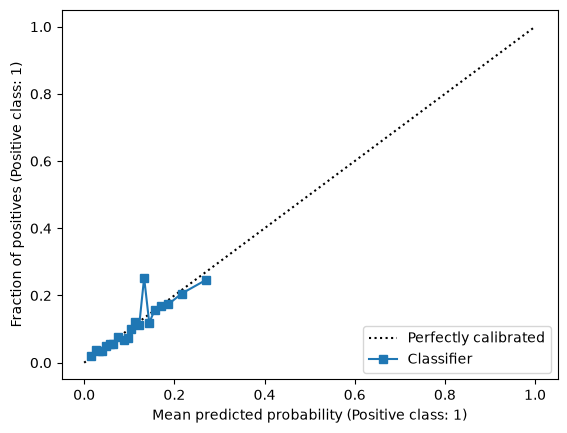

In [128]:
CalibrationDisplay.from_predictions(actual_goals_test, predicted_xG_test, n_bins=20, strategy='quantile')
plt.show()

Calibration curse tell us about how the predicted probaility/outcome behaves accordingly the actual outcome/probability.
ex:
1) if above the diagonal it means shot had more chance of scoring than predicted.- `underestimated`
2) if bellow the diagonal it means shot had less chance of scoring than predicted.- `overestimated`

### Random Forest Ensemble

In [129]:
from sklearn.ensemble import RandomForestClassifier

In [130]:
random_clf_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('random_clf', RandomForestClassifier(random_state=42))
])

In [131]:
random_clf_pipeline.fit(X_train, y_train)

d:\coding\xG_predict\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('random_clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['location_x','location_y','body_part','situation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('body_parts_classification', ...), ('situation_classification', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rema

In [132]:
# predicted xG for trainset
predicted_xG_train = random_clf_pipeline.predict_proba(X_train)[:, 1]
print(mean_absolute_error(xg_train, predicted_xG_train))
print(root_mean_squared_error(xg_train, predicted_xG_train))
actual_goals_train = np.asarray(y_train).ravel()
print(brier_score_loss(actual_goals_train, predicted_xG_train))
print(log_loss(actual_goals_train, predicted_xG_train))

0.10915508332046367
0.18566978319152008
0.02084323707358438
0.0834102905671491


In [133]:
# predicted xG for testset
predicted_xG_test = random_clf_pipeline.predict_proba(X_test)[:, 1]
print(mean_absolute_error(xg_test, predicted_xG_test))
print(root_mean_squared_error(xg_test, predicted_xG_test))
actual_goals_test = np.asarray(y_test).ravel()
print(brier_score_loss(actual_goals_test, predicted_xG_test))
print(log_loss(actual_goals_test, predicted_xG_test))

0.10727137962095425
0.17461871617975286
0.10062279381920906
0.9875162953275651


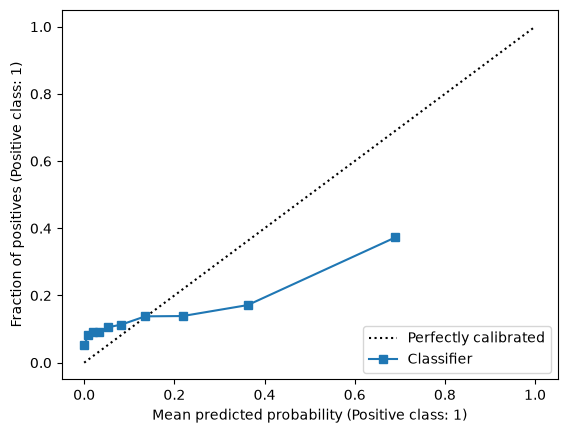

In [134]:
CalibrationDisplay.from_predictions(actual_goals_test, predicted_xG_test, n_bins=15, strategy='quantile')
plt.show()

Performing poor that Logistic model as seen on test set.
1) Higher MAE and RMSE than `Logistic Regressor`.
2) Much Higher brier_score_loss then `Baseline` and `Logistic Regressor`.
3) Much Higher log_loss then `Baseline` and `Logistic Regressor`.
4) Much deviated Calibration curve as had many `underestimated` and `overestimated` points/instances compared to `Logistic Regressor`.

### XGBoost

In [135]:
from xgboost import XGBClassifier

In [136]:
xgboost_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('model', XGBClassifier())
])

In [137]:
xgboost_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['location_x','location_y','body_part','situation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('body_parts_classification', ...), ('situation_classification', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [138]:
# predicted xG for trainset
predicted_xG_train = xgboost_pipeline.predict_proba(X_train)[:, 1]
print(mean_absolute_error(xg_train, predicted_xG_train))
print(root_mean_squared_error(xg_train, predicted_xG_train))
actual_goals_train = np.asarray(y_train).ravel()
print(brier_score_loss(actual_goals_train, predicted_xG_train))
print(log_loss(actual_goals_train, predicted_xG_train))

0.06394290179014206
0.10780826956033707
0.07250232249498367
0.24854084849357605


In [139]:
# predicted xG for testset
predicted_xG_test = xgboost_pipeline.predict_proba(X_test)[:, 1]
print(mean_absolute_error(xg_test, predicted_xG_test))
print(root_mean_squared_error(xg_test, predicted_xG_test))
actual_goals_test = np.asarray(y_test).ravel()
print(brier_score_loss(actual_goals_test, predicted_xG_test))
print(log_loss(actual_goals_test, predicted_xG_test))

0.06595870852470398
0.11178430169820786
0.08275049924850464
0.29594385623931885


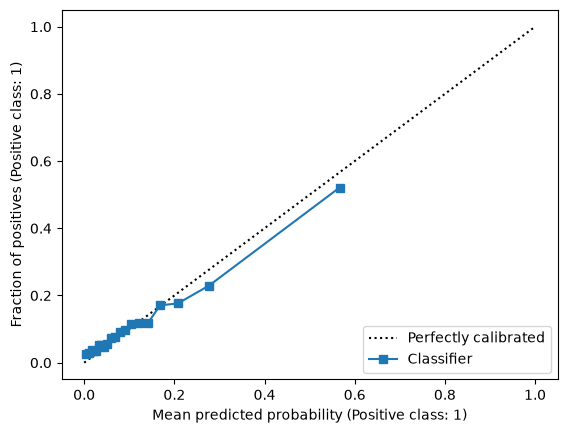

In [140]:
CalibrationDisplay.from_predictions(actual_goals_test, predicted_xG_test, n_bins=20, strategy='quantile')
plt.show()

Perfromed Better than the above two models.
1) Lower MAE and RMSE than `Logistic Regressor` and `Random Forest Classifier`.
2) Much lower brier and log loss than both models and baseline too.

### LightGBM

In [141]:
from lightgbm import LGBMClassifier

In [142]:
lgbm_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('model', LGBMClassifier())
])

In [143]:
lgbm_pipeline.fit(X_train, y_train)

d:\coding\xG_predict\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\coding\xG_predict\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['location_x','location_y','body_part','situation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('body_parts_classification', ...), ('situation_classification', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [144]:
# predicted xG for trainset
predicted_xG_train = lgbm_pipeline.predict_proba(X_train)[:, 1]
print(mean_absolute_error(xg_train, predicted_xG_train))
print(root_mean_squared_error(xg_train, predicted_xG_train))
actual_goals_train = np.asarray(y_train).ravel()
print(brier_score_loss(actual_goals_train, predicted_xG_train))
print(log_loss(actual_goals_train, predicted_xG_train))

0.05934923747793112
0.10213345205137007
0.07739967580517003
0.2678919662471338


In [145]:
# predicted xG for testset
predicted_xG_test = lgbm_pipeline.predict_proba(X_test)[:, 1]
print(mean_absolute_error(xg_test, predicted_xG_test))
print(root_mean_squared_error(xg_test, predicted_xG_test))
actual_goals_test = np.asarray(y_test).ravel()
print(brier_score_loss(actual_goals_test, predicted_xG_test))
print(log_loss(actual_goals_test, predicted_xG_test))

0.06073048163133536
0.10468884702231644
0.08270261062566357
0.293398427078746


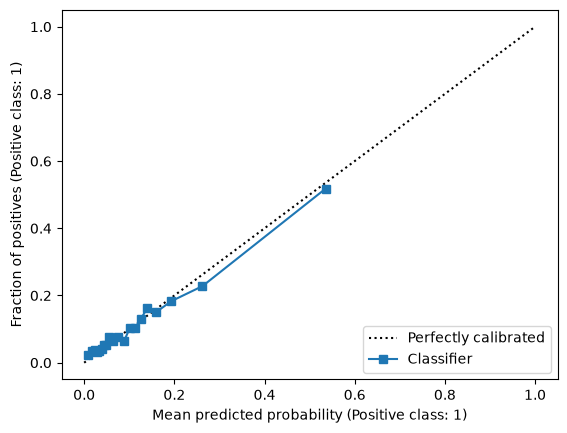

In [146]:
CalibrationDisplay.from_predictions(actual_goals_test, predicted_xG_test, n_bins=20, strategy='quantile')
plt.show()

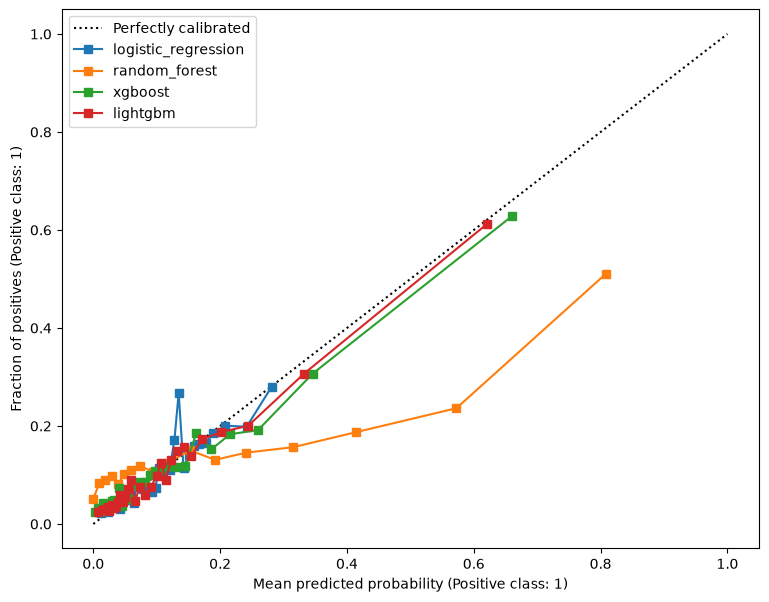

In [149]:
models = [
    ('logistic_regression', logistic_pipeline),
    ('random_forest', random_clf_pipeline),
    ("xgboost", xgboost_pipeline),
    ("lightgbm", lgbm_pipeline)
]
fig, ax = plt.subplots(figsize=(9, 7))
for name, model in models:
    CalibrationDisplay.from_estimator(model, X_test, y_test, n_bins=30, strategy='quantile', name=name, ax=ax)

plt.legend()
plt.show()